<a href="https://colab.research.google.com/github/Adhityawarman03/Tugas_MetNum_Ketut-Adhityawarman/blob/main/25083010029_Ketut_Adhityawarman_Kusuma_Nurjaya_Tugas_Anum_2(revisi).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Perhitungan Volume Lambung Kapal Menggunakan Metode Numerik

Perhitungan ini bertujuan untuk memperkirakan volume satu lambung kapal serta volume gabungan dari dua lambung kapal dengan menerapkan metode numerik, yaitu metode trapesium dan metode Simpson 1/3. Perhitungan didasarkan pada data lebar dan tinggi penampang yang diperoleh dari beberapa titik pengukuran pada gambar.

## Dasar Perhitungan dan Asumsi

Dalam proses estimasi volume lambung kapal, beberapa asumsi dan ketentuan yang digunakan adalah sebagai berikut.

1. Jarak antara dua garis grid pada gambar ditetapkan sebesar 45 cm atau setara dengan 0,45 meter untuk setiap satu kotak penuh.
2. Bagian dasar kapal diasumsikan rata dan tidak menggunakan lunas (*keel*).
3. Bentuk penampang melintang lambung kapal disederhanakan menjadi persegi panjang.
4. Volume tambahan yang berasal dari cadangan daya apung (*reserve buoyancy*) tidak dimasukkan ke dalam perhitungan.
5. Estimasi volume dilakukan pada satu lambung terlebih dahulu. Selanjutnya, volume total dua lambung diperoleh dengan mengasumsikan bahwa keduanya memiliki dimensi dan volume yang identik.
6. Seluruh data ukuran dikonversi ke satuan meter agar hasil akhir perhitungan volume dinyatakan dalam meter kubik (m³).

### Skala Pengukuran

Skala yang dijadikan acuan dalam pengukuran pada gambar adalah:

1 kotak grid=45 cm=0,45 m

Berdasarkan skala tersebut, setiap satu kotak grid penuh menunjukkan panjang sebesar 0,45 meter sepanjang lambung kapal. Pengukuran lebar dan tinggi penampang juga dilakukan berdasarkan jumlah kotak pada gambar, kemudian dikonversi ke satuan meter sebelum digunakan dalam perhitungan numerik.

Dalam tahap ini, kita perlu mengekstrak anggaran kelebaran dan ketinggian lambung utama daripada rajah grid PDF tersebut, kemudian menukarkannya daripada unit kotak grid kepada unit meter menggunakan skala 1 kotak = 0.45 m. Saya telah menetapkan jumlah titik bacaan kepada 25 titik (mewakili 24 selang) supaya kaedah Simpson 1/3 dapat dikira dengan sempurna, memandangkan formula tersebut mewajibkan bilangan selang data genap.

In [1]:
import numpy as np
import pandas as pd

# TAHAP 1: PENETAPAN SKALA DAN DATA GRID
skala_m = 0.45
dx = skala_m # Jarak h (selang) antara stesen pengukuran

# Anggaran bacaan lebar lambung (Tampak Atas) dalam unit kotak
# Jumlah 25 titik data (24 selang)
lebar_kotak = np.array([0, 0.8, 1.2, 1.5, 1.7, 1.9, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0,
                        2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 1.9, 1.7, 1.5, 1.2, 0.8, 0])

# Anggaran bacaan tinggi lambung (Tampak Samping) dalam unit kotak
# Ketinggian lantai dianggap mendatar secara konsisten pada 3 kotak
tinggi_kotak = np.full_like(lebar_kotak, 3.0)

# Penukaran unit kotak kepada unit meter (m)
lebar_m = lebar_kotak * skala_m
tinggi_m = tinggi_kotak * skala_m

# Paparan hasil Tahap 1
df_tahap1 = pd.DataFrame({
    'Titik Pengukuran': np.arange(len(lebar_m)),
    'Lebar (m)': lebar_m,
    'Tinggi (m)': tinggi_m
})

print("=== TAHAP 1: HASIL PENUKARAN SKALA KEPADA METER ===")
print(f"Nilai selang (dx) : {dx} m")
print(f"Jumlah stesen data: {len(lebar_m)} titik\n")
print(df_tahap1.to_string(index=False))

=== TAHAP 1: HASIL PENUKARAN SKALA KEPADA METER ===
Nilai selang (dx) : 0.45 m
Jumlah stesen data: 25 titik

 Titik Pengukuran  Lebar (m)  Tinggi (m)
                0      0.000        1.35
                1      0.360        1.35
                2      0.540        1.35
                3      0.675        1.35
                4      0.765        1.35
                5      0.855        1.35
                6      0.900        1.35
                7      0.900        1.35
                8      0.900        1.35
                9      0.900        1.35
               10      0.900        1.35
               11      0.900        1.35
               12      0.900        1.35
               13      0.900        1.35
               14      0.900        1.35
               15      0.900        1.35
               16      0.900        1.35
               17      0.900        1.35
               18      0.900        1.35
               19      0.855        1.35
               20      0.765  

Berdasarkan asumsi nomor, penampang melintang kapal dianggap berbentuk persegi panjang. Artinya, untuk mencari luas penampang di setiap titik potongnya, kita tinggal mengalikan lebar dengan tingginya ($Luas = Lebar \times Tinggi$).

In [2]:
# TAHAP 2: PERHITUNGAN LUAS PENAMPANG
# Asumsi 3: Penampang melintang berbentuk persegi panjang

# Menghitung luas (Lebar x Tinggi)
luas_penampang_m2 = lebar_m * tinggi_m

# Memasukkan hasil perhitungan luas ke dalam DataFrame agar rapi
df_tahap2 = df_tahap1.copy()
df_tahap2['Luas Penampang (m^2)'] = luas_penampang_m2

print("=== TAHAP 2: HASIL PERHITUNGAN LUAS PENAMPANG ===")
print("Rumus yang digunakan: Luas = Lebar x Tinggi\n")
print(df_tahap2.to_string(index=False))

=== TAHAP 2: HASIL PERHITUNGAN LUAS PENAMPANG ===
Rumus yang digunakan: Luas = Lebar x Tinggi

 Titik Pengukuran  Lebar (m)  Tinggi (m)  Luas Penampang (m^2)
                0      0.000        1.35               0.00000
                1      0.360        1.35               0.48600
                2      0.540        1.35               0.72900
                3      0.675        1.35               0.91125
                4      0.765        1.35               1.03275
                5      0.855        1.35               1.15425
                6      0.900        1.35               1.21500
                7      0.900        1.35               1.21500
                8      0.900        1.35               1.21500
                9      0.900        1.35               1.21500
               10      0.900        1.35               1.21500
               11      0.900        1.35               1.21500
               12      0.900        1.35               1.21500
               13      

Di tahap ini, kita akan menjumlahkan semua luas penampang yang udah didapat di Tahap 2 menggunakan dua metode integrasi numerik sesuai permintaan soal. Setelah dapat volume satu lambung, kita tinggal kali dua untuk dapat total volume perahu katamarannya.

In [3]:
from scipy.integrate import trapezoid, simpson

# TAHAP 3: INTEGRASI NUMERIK UNTUK VOLUME LAMBUNG
# Menggunakan data luas_penampang_m2 dan jarak antar grid (dx = 0.45 m)

# 1. Metode Trapesium
vol_trapz_1_lambung = trapezoid(y=luas_penampang_m2, dx=dx)
vol_trapz_total = vol_trapz_1_lambung * 2

# 2. Metode Simpson 1/3
vol_simp_1_lambung = simpson(y=luas_penampang_m2, dx=dx)
vol_simp_total = vol_simp_1_lambung * 2

# Menampilkan Hasil Akhir
print("=== TAHAP 3: HASIL PERHITUNGAN VOLUME KAPAL (m^3) ===")
print("A. METODE TRAPESIUM")
print(f"   - Volume 1 lambung           : {vol_trapz_1_lambung:.4f} m^3")
print(f"   - Total Volume (2 lambung)   : {vol_trapz_total:.4f} m^3\n")

print("B. METODE SIMPSON 1/3")
print(f"   - Volume 1 lambung           : {vol_simp_1_lambung:.4f} m^3")
print(f"   - Total Volume (2 lambung)   : {vol_simp_total:.4f} m^3")

=== TAHAP 3: HASIL PERHITUNGAN VOLUME KAPAL (m^3) ===
A. METODE TRAPESIUM
   - Volume 1 lambung           : 10.9897 m^3
   - Total Volume (2 lambung)   : 21.9794 m^3

B. METODE SIMPSON 1/3
   - Volume 1 lambung           : 11.0443 m^3
   - Total Volume (2 lambung)   : 22.0887 m^3


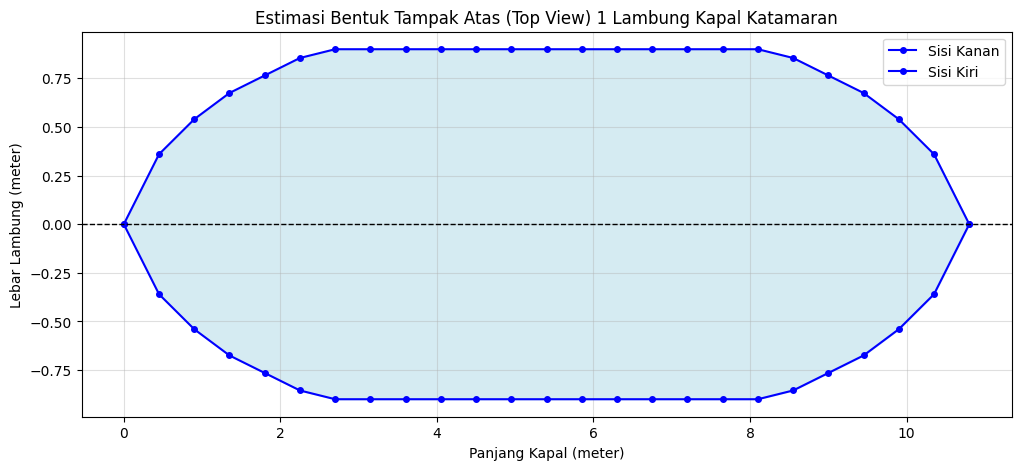


=== KESIMPULAN AKHIR ===
Dari visualisasi di atas, data grid telah berhasil merepresentasikan bentuk lambung kapal.
Berdasarkan perhitungan integrasi numerik untuk bentuk tersebut:
Total Volume 2 Lambung (Trapesium)   : 21.9794 m^3
Total Volume 2 Lambung (Simpson 1/3) : 22.0887 m^3
Catatan: Metode Simpson 1/3 umumnya memberikan hasil lebih akurat untuk kurva melengkung seperti lambung kapal.


In [4]:
import matplotlib.pyplot as plt

# TAHAP 4: VISUALISASI PROFIL LAMBUNG (TAMPAK ATAS) & KESIMPULAN
# Menggambarkan bentuk lambung dari atas untuk memverifikasi bentuk data

plt.figure(figsize=(12, 5))

# Sumbu X adalah panjang kapal (jumlah titik dikali jarak grid dx)
sumbu_x = np.arange(len(lebar_m)) * dx

# Plot sisi kanan dan sisi kiri lambung (karena bentuknya simetris)
plt.plot(sumbu_x, lebar_m, label='Sisi Kanan', color='blue', marker='.', markersize=8)
plt.plot(sumbu_x, -lebar_m, label='Sisi Kiri', color='blue', marker='.', markersize=8)

# Memberi warna pada area lambung
plt.fill_between(sumbu_x, lebar_m, -lebar_m, color='lightblue', alpha=0.5)

# Kustomisasi grafik
plt.title('Estimasi Bentuk Tampak Atas (Top View) 1 Lambung Kapal Katamaran')
plt.xlabel('Panjang Kapal (meter)')
plt.ylabel('Lebar Lambung (meter)')
plt.axhline(0, color='black', linewidth=1, linestyle='--')
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()

print("\n=== KESIMPULAN AKHIR ===")
print("Dari visualisasi di atas, data grid telah berhasil merepresentasikan bentuk lambung kapal.")
print("Berdasarkan perhitungan integrasi numerik untuk bentuk tersebut:")
print(f"Total Volume 2 Lambung (Trapesium)   : {vol_trapz_total:.4f} m^3")
print(f"Total Volume 2 Lambung (Simpson 1/3) : {vol_simp_total:.4f} m^3")
print("Catatan: Metode Simpson 1/3 umumnya memberikan hasil lebih akurat untuk kurva melengkung seperti lambung kapal.")